# 05d — From records to toads: the probability that toads are present

Notebooks 05–05c modelled the **first record** of a toad in each cell. But a record needs two things: toads must be there, and someone must find and report them. What matters for management is the first one:

> **What is the probability that toads are present in each 25 km cell in year X?**

Notebook 05c showed why the difference matters: survey effort changes the chance of a first record 20- to 100-fold, and cells surrounded by toads can stay without records for years.

### The model

Two processes, in the spirit of dynamic occupancy models with imperfect detection (MacKenzie et al. 2002, 2003):

1. **Detection.** In cells that already have toads, what is the chance of recording them in a given year? It depends on survey effort (records of other amphibians in that cell and year) and region. It is estimated from the years *after* each cell's first record, assuming toads do not disappear once they arrive.
2. **Arrival.** Every year, toads arrive in an empty cell with a probability that depends on the distance to occupied cells, the number of occupied neighbours, climate suitability and region (faster outside Queensland, notebook 05c). The arrival year is not observed: the first record happens at arrival plus a detection delay, so the likelihood sums over all possible arrival years.

**Assumption:** no local extinction. **Approximation:** neighbourhood features use the *recorded* occupancy, not the (unknown) true presence.

**Uncertainty:** a spatial block bootstrap. Blocks of 250 × 250 km are resampled with replacement, both models are refitted, and each simulation run uses one of the refitted models. So the intervals include the uncertainty of the coefficients, not only the randomness of the simulation.

**Validation:** true presence is never observed, so the model is tested on what it implies for **records** (presence × detection), with the same backtests as before and proper scoring rules (Gneiting & Raftery 2007).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy.special import expit, log_expit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))
from colonization import FEATURES, cell_year_table, simulate
from environment import BIOCLIM_VARIABLES, environmental_grid
from front import records_to_cells
from occupancy import ArrivalLikelihood, counts_per_cell_year, fit_detection, simulate_presence, value_at

PROCESSED, RAW = PROJECT_ROOT / "data" / "processed", PROJECT_ROOT / "data" / "raw"
FIGURES = PROJECT_ROOT / "figures"
CELL_SIZE_M = 25_000
CELL_KM2 = (CELL_SIZE_M / 1000) ** 2
CLIMATE = list(BIOCLIM_VARIABLES.values())
TRAIN_START = 1990
N_BOOTSTRAP = 30
BLOCK_CELLS = 10  # 10 x 25 km = 250 km blocks

cells = environmental_grid(CELL_SIZE_M)
toads = pd.read_csv(PROCESSED / "rhinella_marina_clean.csv")
cells = cells.merge(records_to_cells(toads, CELL_SIZE_M)[["cx", "cy", "first_year"]], how="left", on=["cx", "cy"])
cells["first_year"] = cells["first_year"].fillna(np.inf)
cells["x_km"] = (cells["cx"] + 0.5) * CELL_SIZE_M / 1000
cells["y_km"] = (cells["cy"] + 0.5) * CELL_SIZE_M / 1000
first_year = cells["first_year"].to_numpy()
x_km = cells["x_km"].to_numpy()
west = (cells["lon"] < 141).to_numpy()
outside = (cells["lon"] < 138).astype(int).to_numpy()
desert = (cells["climate_zone"] == "Desert (BW)").to_numpy()
pilbara = (cells["lon"].between(116, 121) & cells["lat"].between(-23, -19)).to_numpy()

amphibians = pd.read_csv(RAW / "amphibia_ala.csv", low_memory=False)
others = amphibians.loc[
    (amphibians["scientificName"] != "Rhinella marina")
    & amphibians["decimalLatitude"].notna() & amphibians["year"].notna()
    & ~(amphibians["coordinateUncertaintyInMeters"] > 10_000)
]
effort = counts_per_cell_year(others, cells, CELL_SIZE_M)
toad_counts = counts_per_cell_year(toads.dropna(subset=["year"]), cells, CELL_SIZE_M)
print(f"{len(cells):,} cells; effort records {int(effort.to_numpy().sum()):,}; toad records {int(toad_counts.to_numpy().sum()):,}")

12,312 cells; effort records 1,843,125; toad records 34,607


## 1. Detection: if toads are there, how often are they recorded?

In [2]:
REGION = ["outside_queensland", "outside_x_log_distance", "outside_x_neighbours_50km"]
ARRIVAL = FEATURES + REGION
DETECTION = ["log_effort", "outside_queensland"]


def region_terms(table: pd.DataFrame, cell_ids: np.ndarray) -> pd.DataFrame:
    flag = outside[cell_ids]
    table["outside_queensland"] = flag
    table["outside_x_log_distance"] = flag * table["log_distance_km"].to_numpy()
    table["outside_x_neighbours_50km"] = flag * table["neighbours_50km"].to_numpy()
    return table


def detection_table(cutoff: int) -> pd.DataFrame:
    '''Cell-years after each cell's first record, up to the cut-off: toads are there, were they recorded?'''
    occupied = np.flatnonzero(first_year < cutoff)
    start = np.maximum(first_year[occupied].astype(int) + 1, TRAIN_START)
    lengths = np.clip(cutoff - start + 1, 0, None)
    cell_ids = np.repeat(occupied, lengths)
    years = np.concatenate([np.arange(s, cutoff + 1) for s in start])
    table = pd.DataFrame({"cell": cell_ids, "year": years})
    table["log_effort"] = np.log1p(value_at(effort, cell_ids, years))
    table["outside_queensland"] = outside[cell_ids]
    table["detected"] = (value_at(toad_counts, cell_ids, years) > 0).astype(int)
    return table


detection_2025 = detection_table(2025)
detection_fit = fit_detection(detection_2025, DETECTION)
grid = pd.DataFrame({"log_effort": np.log1p(np.repeat([0, 1, 3, 10, 30, 100], 2)), "outside_queensland": [0, 1] * 6})
grid["P(recorded | present)"] = expit(detection_fit.linear(grid))
grid.insert(0, "other amphibian records", np.expm1(grid["log_effort"]).round().astype(int))
print(f"{len(detection_2025):,} cell-years after the first record; toads recorded in {detection_2025['detected'].mean():.1%}")
grid.drop(columns="log_effort").round(3)

29,466 cell-years after the first record; toads recorded in 12.6%


,other amphibian records,outside_queensland,P(recorded | present)
0,0,0,0.032
1,0,1,0.075
2,1,0,0.066
3,1,1,0.146
4,3,0,0.132
5,3,1,0.268
6,10,0,0.314
7,10,1,0.525
8,30,0,0.586
9,30,1,0.774


### Checking the no-extinction assumption

If toads died out in some cells (for example at the dry margins), those cells would be recorded **less often than the detection model expects** for their survey effort. Observed vs expected detection by climate zone:

In [3]:
check = detection_2025.assign(
    expected=expit(detection_fit.linear(detection_2025)),
    zone=cells["climate_zone"].to_numpy()[detection_2025["cell"]],
)
by_zone = check.groupby("zone")[["detected", "expected"]].agg(["sum", "size"])
by_zone = pd.DataFrame({
    "cell-years": by_zone[("detected", "size")],
    "observed detections": by_zone[("detected", "sum")],
    "expected detections": check.groupby("zone")["expected"].sum().round(1),
})
by_zone["observed / expected"] = (by_zone["observed detections"] / by_zone["expected detections"]).round(2)
by_zone

,cell-years,observed detections,expected detections,observed / expected
zone,,,,
Desert (BW),62,3,4.6,0.65
"Humid, summer rain",21678,3141,2865.1,1.10
"Humid, year-round rain",907,243,425.8,0.57
Semi-arid (BS),6819,324,415.5,0.78


## 2. Arrival, with the arrival year as a latent variable

In [4]:
def suitability(cutoff: int) -> np.ndarray:
    model = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LogisticRegression(max_iter=5000))
    return model.fit(cells[CLIMATE], (cells["first_year"] <= cutoff).astype(int)).predict_proba(cells[CLIMATE])[:, 1]


def arrival_table(cutoff: int, score: np.ndarray) -> pd.DataFrame:
    table = cell_year_table(cells, score, range(TRAIN_START, cutoff + 1))
    table["log_effort"] = np.log1p(value_at(effort, table["cell"].to_numpy(), table["year"].to_numpy()))
    return region_terms(table, table["cell"].to_numpy())


def with_detection(table: pd.DataFrame, fit) -> pd.DataFrame:
    eta = fit.linear(table)
    return table.assign(log_detection=log_expit(eta), log1m_detection=log_expit(-eta))


def fit_both(cutoff: int, table: pd.DataFrame, cell_weights: pd.Series | None = None):
    detection = detection_table(cutoff)
    row_weights = None if cell_weights is None else cell_weights.reindex(detection["cell"]).fillna(0).to_numpy()
    detection_model = fit_detection(detection, DETECTION, row_weights)
    likelihood = ArrivalLikelihood(with_detection(table, detection_model), ARRIVAL, cell_weights)
    return likelihood.fit(), detection_model, likelihood


suitability_2025 = suitability(2025)
table_2025 = arrival_table(2025, suitability_2025)
arrival_fit, detection_fit, likelihood_2025 = fit_both(2025, table_2025)
pd.Series(arrival_fit.coef, index=["intercept"] + ARRIVAL, name="coefficient (per SD)").round(2).to_frame()

,coefficient (per SD)
intercept,-8.73
log_distance_km,-0.83
neighbours_50km,0.31
neighbours_100km,-0.11
suitability_logit,1.61
outside_queensland,2.14
outside_x_log_distance,-2.43
outside_x_neighbours_50km,-0.18


## 3. Where are toads now, recorded or not?

For a cell without records, the posterior probability of presence weighs two explanations: toads never arrived, or they arrived and nobody recorded them.

Cells with records by 2025: 1,289
Expected cells with toads but no record: 560 (262 with P > 0.5)
'Holes' (no record, at least 6 of 8 neighbours with records): 86, median P(present) = 0.79


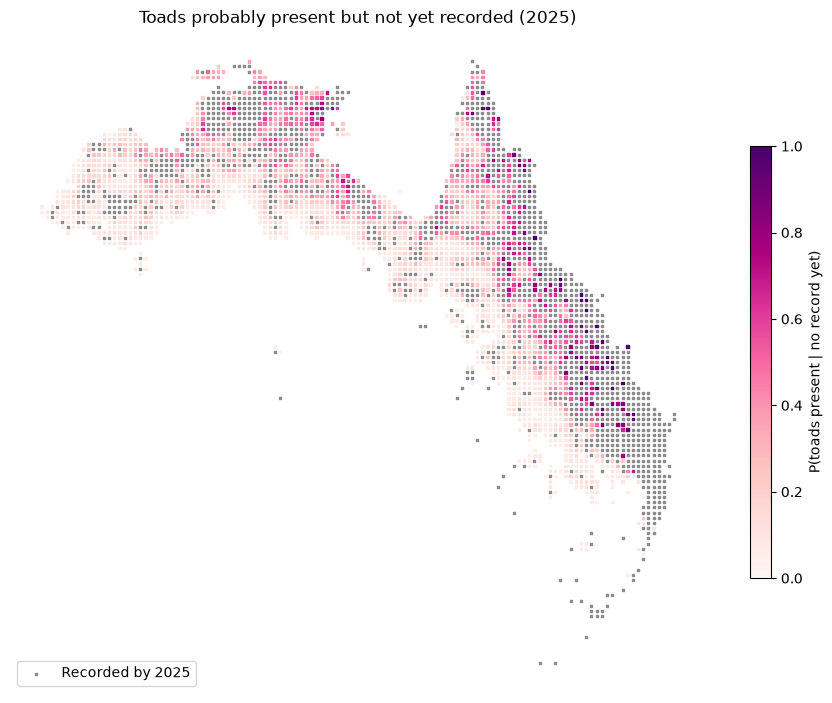

In [5]:
posterior_2025 = likelihood_2025.presence_posterior(arrival_fit).reindex(range(len(cells))).fillna(1.0).to_numpy()
recorded_2025 = first_year <= 2025
unrecorded = ~recorded_2025
print(f"Cells with records by 2025: {recorded_2025.sum():,}")
print(f"Expected cells with toads but no record: {posterior_2025[unrecorded].sum():.0f} "
      f"({(posterior_2025[unrecorded] > 0.5).sum()} with P > 0.5)")

occupied_tree = cKDTree(cells.loc[recorded_2025, ["cx", "cy"]].to_numpy())
neighbours = np.array([len(n) for n in occupied_tree.query_ball_point(cells[["cx", "cy"]].to_numpy(), r=1.5)])
holes = unrecorded & (neighbours >= 6)
print(f"'Holes' (no record, at least 6 of 8 neighbours with records): {holes.sum()}, "
      f"median P(present) = {np.median(posterior_2025[holes]):.2f}")

fig, ax = plt.subplots(figsize=(9, 7.5))
shown = unrecorded & (posterior_2025 >= 0.05)
ax.scatter(x_km[recorded_2025], cells["y_km"][recorded_2025], s=3, marker="s", color="0.55", label="Recorded by 2025")
image = ax.scatter(x_km[shown], cells["y_km"][shown], c=posterior_2025[shown], s=3, marker="s", cmap="RdPu", vmin=0, vmax=1)
plt.colorbar(image, ax=ax, shrink=0.6, label="P(toads present | no record yet)")
ax.set_aspect("equal"); ax.set_axis_off(); ax.legend(loc="lower left")
ax.set_title("Toads probably present but not yet recorded (2025)")
plt.tight_layout()
plt.savefig(FIGURES / "05d_unrecorded_presence_2025.png", dpi=150)

## 4. Spatial block bootstrap

In [6]:
blocks = (cells["cx"] // BLOCK_CELLS).astype(str) + "_" + (cells["cy"] // BLOCK_CELLS).astype(str)
block_ids = blocks.unique()


def bootstrap_fits(cutoff: int, table: pd.DataFrame, n: int = N_BOOTSTRAP, seed: int = 0):
    rng = np.random.default_rng(seed)
    fits = []
    for _ in range(n):
        drawn = pd.Series(rng.choice(block_ids, size=len(block_ids), replace=True)).value_counts()
        weights = pd.Series(blocks.map(drawn).fillna(0).to_numpy(), index=range(len(cells)))
        arrival, detection, _ = fit_both(cutoff, table, weights)
        fits.append((arrival, detection))
    return fits


fits_2025 = bootstrap_fits(2025, table_2025)
spread = pd.DataFrame([f[0].coef for f in fits_2025], columns=["intercept"] + ARRIVAL)
spread.describe().loc[["mean", "std", "min", "max"]].round(2)

,intercept,log_distance_km,neighbours_50km,neighbours_100km,suitability_logit,outside_queensland,outside_x_log_distance,outside_x_neighbours_50km
mean,-8.79,-0.83,0.33,-0.13,1.64,2.26,-2.58,-0.22
std,0.39,0.19,0.06,0.07,0.23,0.39,0.52,0.07
min,-9.52,-1.18,0.19,-0.28,1.13,1.55,-3.75,-0.40
max,-8.20,-0.58,0.44,0.09,2.04,3.13,-1.55,-0.12


## 5. Backtests: what the model implies for records

For each cut-off (2015 and 2020), everything is refitted with data up to the cut-off (suitability, detection, arrival and the bootstrap), the presence of toads in unrecorded cells at the cut-off is drawn from its posterior, and arrival and detection are simulated year by year to 2025.

Future survey effort is unknown to a forecaster, so the **honest** version freezes effort at its mean over the 3 years before the cut-off. A second version uses the effort actually recorded, to separate errors of the ecology from errors in predicting effort. The reference is the record model of notebook 05.

In [7]:
N_RUNS = 50
FAR_KM = 300


def western_front(occupied: np.ndarray) -> float:
    return np.sort(x_km[occupied & west])[2]


def effort_function(mode: str, cutoff: int):
    if mode == "observed":
        return lambda year: np.log1p(value_at(effort, np.arange(len(cells)), np.full(len(cells), year)))
    columns = [y for y in range(cutoff - 2, cutoff + 1) if y in effort.columns]
    frozen = np.log1p(effort[columns].mean(axis=1).to_numpy())
    return lambda year: frozen


def add_region(table: pd.DataFrame, year: int) -> pd.DataFrame:
    return region_terms(table, table.index.to_numpy())


def evaluate(records: np.ndarray, cutoff: int, end: int = 2025) -> dict:
    occupied = records <= end
    occupied_cutoff = first_year <= cutoff
    observed_end = first_year <= end
    new = ~occupied_cutoff
    beyond = west & (x_km < western_front(occupied_cutoff)) & new
    distance, _ = cKDTree(cells.loc[occupied_cutoff, ["x_km", "y_km"]].to_numpy()).query(cells[["x_km", "y_km"]].to_numpy())
    far = new & (distance > FAR_KM)
    p = np.clip(occupied.mean(axis=0)[new], 1e-3, 1 - 1e-3)
    y = observed_end[new].astype(float)
    return {
        "AUC": roc_auc_score(y, p),
        "Brier score": np.mean((p - y) ** 2),
        "log loss": -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)),
        "new cells: observed": int(y.sum()),
        "new cells: simulated (median)": np.median(occupied[:, new].sum(axis=1)),
        "west of cut-off front: observed": int(observed_end[beyond].sum()),
        "west of cut-off front: simulated": occupied[:, beyond].sum(axis=1).mean(),
        f">{FAR_KM} km from the range: observed": int(observed_end[far].sum()),
        f">{FAR_KM} km from the range: simulated": occupied[:, far].sum(axis=1).mean(),
        "front error (km)": np.median([western_front(r) for r in occupied]) - western_front(observed_end),
    }


def reference_records(cutoff: int, score: np.ndarray) -> np.ndarray:
    '''The record model of notebook 05: distance, neighbours and suitability, no detection.'''
    table = cell_year_table(cells, score, range(TRAIN_START, cutoff + 1))
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(table[FEATURES], table["colonised"])
    return simulate(model, cells, score, cutoff, range(cutoff + 1, 2026), n_runs=N_RUNS)


backtest_runs, results, posteriors = {}, {}, {}
for cutoff in [2015, 2020]:
    score = suitability(cutoff)
    table = arrival_table(cutoff, score)
    main_arrival, main_detection, likelihood = fit_both(cutoff, table)
    posterior = likelihood.presence_posterior(main_arrival).reindex(range(len(cells))).fillna(1.0).to_numpy()
    posteriors[cutoff] = np.where(first_year <= cutoff, 1.0, posterior)
    fits = bootstrap_fits(cutoff, table, seed=cutoff)
    backtest_runs[(cutoff, "notebook 05 (records)")] = reference_records(cutoff, score)
    for mode in ["frozen", "observed"]:
        arrivals, records = simulate_presence(fits, cells, score, cutoff, range(cutoff + 1, 2026), posteriors[cutoff],
                                              effort_function(mode, cutoff), add_region, n_runs=N_RUNS, seed=1)
        backtest_runs[(cutoff, f"presence model, {mode} effort")] = records
        backtest_runs[(cutoff, f"presence model, {mode} effort: presence")] = arrivals
    for label in ["notebook 05 (records)", "presence model, frozen effort", "presence model, observed effort"]:
        results[(cutoff, label)] = evaluate(backtest_runs[(cutoff, label)], cutoff)

comparison = pd.DataFrame(results).T
comparison.index.names = ["trained up to", "model"]
reference = comparison.xs("notebook 05 (records)", level="model")["Brier score"]
comparison["Brier skill vs notebook 05"] = 1 - comparison["Brier score"] / comparison.index.get_level_values(0).map(reference)
comparison.round(3)

AUC  Brier score  log loss  \
trained up to model                                                           
2015          notebook 05 (records)            0.829        0.025     0.108   
              presence model, frozen effort    0.872        0.025     0.098   
              presence model, observed effort  0.902        0.023     0.087   
2020          notebook 05 (records)            0.774        0.016     0.079   
              presence model, frozen effort    0.841        0.015     0.070   
              presence model, observed effort  0.881        0.014     0.061   

                                               new cells: observed  \
trained up to model                                                  
2015          notebook 05 (records)                          313.0   
              presence model, frozen effort                  313.0   
              presence model, observed effort                313.0   
2020          notebook 05 (records)                          187.0   
              presence model, frozen effort                  187.0   
              presence model, observed effort                187.0   

                                               new cells: simulated (median)  \
trained up to model                                                            
2015          notebook 05 (records)                                    186.5   
              presence model, frozen effort                            315.5   
              presence model, observed effort                          370.5   
2020          notebook 05 (records)                                    102.5   
              presence model, frozen effort                            163.0   
              presence model, observed effort                          183.0   

                                               west of cut-off front: observed  \
trained up to model                                                              
2015          notebook 05 (records)                                       58.0   
              presence model, frozen effort                               58.0   
              presence model, observed effort                             58.0   
2020          notebook 05 (records)                                        8.0   
              presence model, frozen effort                                8.0   
              presence model, observed effort                              8.0   

                                               west of cut-off front: simulated  \
trained up to model                                                               
2015          notebook 05 (records)                                       11.28   
              presence model, frozen effort                               15.70   
              presence model, observed effort                             14.74   
2020          notebook 05 (records)                                        1.94   
              presence model, frozen effort                                1.92   
              presence model, observed effort                              2.00   

                                               >300 km from the range: observed  \
trained up to model                                                               
2015          notebook 05 (records)                                         7.0   
              presence model, frozen effort                                 7.0   
              presence model, observed effort                               7.0   
2020          notebook 05 (records)                                         0.0   
              presence model, frozen effort                                 0.0   
              presence model, observed effort                               0.0   

                                               >300 km from the range: simulated  \
trained up to model                                                                
2015          notebook 05 (records)                        

## 6. Calibration

Cells are grouped by the predicted probability of having a record by 2025; within each group, the share that actually got one should match. On the diagonal = believable percentages.

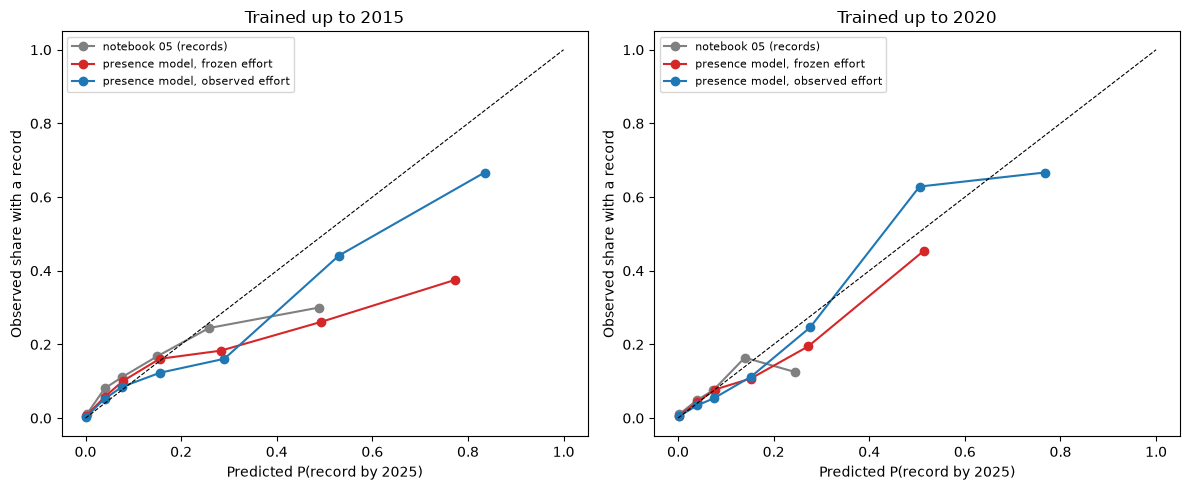

In [8]:
BINS = [0, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, cutoff in zip(axes, [2015, 2020]):
    new = first_year > cutoff
    for label, colour in [("notebook 05 (records)", "grey"), ("presence model, frozen effort", "tab:red"),
                          ("presence model, observed effort", "tab:blue")]:
        p = (backtest_runs[(cutoff, label)] <= 2025).mean(axis=0)[new]
        y = (first_year <= 2025)[new]
        groups = pd.DataFrame({"p": p, "y": y, "bin": pd.cut(p, BINS, include_lowest=True)}).groupby("bin", observed=True)
        curve = groups.agg(predicted=("p", "mean"), observed=("y", "mean"))
        ax.plot(curve["predicted"], curve["observed"], "o-", color=colour, label=label)
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
    ax.set(xlabel="Predicted P(record by 2025)", ylabel="Observed share with a record", title=f"Trained up to {cutoff}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "05d_calibration.png", dpi=150)

## 7. Forecast 2026–2035 and outputs for the page

Effort is frozen at its 2023–2025 mean. Saved per cell and year: P(toads present) and P(toad recorded), for the test trained up to 2020 (2021–2025) and for the forecast trained up to 2025 (2026–2035), with and without the desert limit of notebook 05b (desert cells cannot be colonised).

In [9]:
N_RUNS_FORECAST = 200
cell_columns = cells[["cx", "cy", "lon", "lat", "first_year"]].reset_index(drop=True)
summaries = []
fits_by_cutoff = {2025: fits_2025}
for desert_limit in [False, True]:
    scenario = "presence model" + (", desert limit" if desert_limit else "")
    name = scenario.replace(", ", "_").replace(" ", "_")
    for period, cutoff, years, n_runs in [("backtest", 2020, range(2021, 2026), N_RUNS),
                                          ("forecast", 2025, range(2026, 2036), N_RUNS_FORECAST)]:
        score = suitability(cutoff)
        if cutoff not in fits_by_cutoff:
            fits_by_cutoff[cutoff] = bootstrap_fits(cutoff, arrival_table(cutoff, score), seed=cutoff)
        initial = posteriors.get(cutoff, np.where(first_year <= 2025, 1.0, posterior_2025))
        sim_score = np.where(desert, 0.0, score) if desert_limit else score
        arrivals, records = simulate_presence(fits_by_cutoff[cutoff], cells, sim_score, cutoff, years, initial,
                                              effort_function("frozen", cutoff), add_region, n_runs=n_runs, seed=2)
        for measure, simulated in [("presence", arrivals), ("records", records)]:
            probability = pd.DataFrame({f"p_{year}": (simulated <= year).mean(axis=0) for year in [cutoff, *years]})
            pd.concat([cell_columns, probability], axis=1).to_csv(PROCESSED / f"{period}_{measure}_{name}.csv", index=False)
            for year in years:
                occupied = simulated <= year
                area = occupied.sum(axis=1) * CELL_KM2
                front = np.array([western_front(r) for r in occupied])
                summaries.append({
                    "scenario": scenario, "measure": measure, "period": period, "year": year,
                    "area_median": np.median(area), "area_p5": np.percentile(area, 5), "area_p95": np.percentile(area, 95),
                    "front_x_median": np.median(front), "front_x_p5": np.percentile(front, 5), "front_x_p95": np.percentile(front, 95),
                    "p_pilbara": occupied[:, pilbara].any(axis=1).mean(),
                })
summary = pd.DataFrame(summaries)
summary.to_csv(PROCESSED / "simulation_summary_by_year_presence.csv", index=False)
summary.loc[summary["year"].isin([2025, 2030, 2035])].round(2)

,scenario,measure,period,year,area_median,area_p5,area_p95,front_x_median,front_x_p5,front_x_p95,p_pilbara
4,presence model,presence,backtest,2025,1185937.5,1139000.00,1240125.00,-887.5,-1151.25,-773.75,0.42
9,presence model,records,backtest,2025,790625.0,770906.25,812218.75,-737.5,-851.25,-737.50,0.18
14,presence model,presence,forecast,2030,1263437.5,1237468.75,1303187.50,-962.5,-1240.00,-887.50,0.36
19,presence model,presence,forecast,2035,1360937.5,1326781.25,1435625.00,-1037.5,-1588.75,-912.50,0.54
24,presence model,records,forecast,2030,908750.0,893656.25,928156.25,-887.5,-1012.50,-862.50,0.10
29,presence model,records,forecast,2035,1010625.0,986218.75,1041281.25,-937.5,-1438.75,-887.50,0.26
34,"presence model, desert limit",presence,backtest,2025,1180625.0,1146218.75,1234843.75,-812.5,-987.50,-762.50,0.24
39,"presence model, desert limit",records,backtest,2025,786875.0,770000.00,809375.00,-737.5,-853.75,-737.50,0.06
44,"presence model, desert limit",presence,forecast,2030,1260937.5,1233125.00,1295031.25,-962.5,-1087.50,-887.50,0.28
49,"presence model, desert limit",presence,forecast,2035,1353125.0,1317500.00,1421906.25,-1012.5,-1265.00,-912.50,0.34


## Takeaways

- **Detection is low where few people look.** In a cell with toads and no other amphibian records that year, the chance of recording a toad is about 3% per year in Queensland and 8% elsewhere; with 10 other records it rises to 31–53%. A poorly surveyed cell can host toads for many years without a record.
- **About 560 cells probably have toads but no record yet (2025).** Cells surrounded by recorded cells have a median probability of presence of 0.79, where the record model gave them about 0.2 by 2035.
- **The presence model forecasts records better than every record model.** Against notebook 05, the log loss drops 9% (trained up to 2015) and 11% (up to 2020) in the honest version with frozen effort, and 19–23% with the effort actually recorded; the AUC rises from 0.83 to 0.87 and from 0.77 to 0.84. With frozen effort it reproduces the number of new cells trained up to 2015 (316 simulated vs 313 observed) and has fewer spurious long jumps. Unlike the record models of notebook 05c, the proper scoring rules improve, not only the counts.
- **Calibration:** with the effort actually recorded, the probabilities are close to the diagonal (trained up to 2020). With frozen effort, the model is still overconfident at high probabilities: part of the remaining error is not knowing where people will look.
- **What it does not fix:** the western front still lags by ~125 km in both backtests, and the cells beyond the cut-off front are underpredicted (16 vs 58, trained up to 2015).
- **The no-extinction assumption is questionable at the dry margins:** in occupied semi-arid cells, toads are recorded 22% less often than the detection model expects.
- **Reading P(Pilbara):** the probability of *any* toad presence in the Pilbara box is driven by many cells with a tiny probability each (rare long-distance arrivals that cannot be ruled out where nobody looks for frogs). It is a measure of risk, not a prediction that the front will be there.